In [1]:
import sys
print(sys.executable)

/home/shantanu/anaconda3/envs/toi700/bin/python


In [2]:
import numpy, scipy, pandas, matplotlib, astropy, emcee, corner, dynesty
import lightkurve, wotan, batman
print("lightkurve", lightkurve.__version__)
print("batman", batman.__version__)

/home/shantanu/anaconda3/envs/toi700/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


lightkurve 2.6.0
batman 2.5.1


/home/shantanu/anaconda3/envs/toi700/lib/python3.11/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [3]:
import lightkurve as lk

search = lk.search_lightcurve("TIC 150428135", mission="TESS", author="SPOC", exptime=120)
print(search)


SearchResult containing 37 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   150428135      0.0
  1 TESS Sector 03 2018   SPOC     120   150428135      0.0
  2 TESS Sector 04 2018   SPOC     120   150428135      0.0
  3 TESS Sector 05 2018   SPOC     120   150428135      0.0
  4 TESS Sector 06 2018   SPOC     120   150428135      0.0
  5 TESS Sector 07 2019   SPOC     120   150428135      0.0
  6 TESS Sector 08 2019   SPOC     120   150428135      0.0
  7 TESS Sector 09 2019   SPOC     120   150428135      0.0
  8 TESS Sector 10 2019   SPOC     120   150428135      0.0
  9 TESS Sector 11 2019   SPOC     120   150428135      0.0
 10 TESS Sector 13 2019   SPOC     120   150428135      0.0
 11 TESS Sector 27 2020   SPOC     120   150428135      0.0
 12 TESS Sector 28 2020   SPOC     120   150428135      0

1 TIC 150428135
<TableColumns names=('time','flux','flux_err','timecorr','cadenceno','centroid_col','centroid_row','sap_flux','sap_flux_err','sap_bkg','sap_bkg_err','pdcsap_flux','pdcsap_flux_err','quality','psf_centr1','psf_centr1_err','psf_centr2','psf_centr2_err','mom_centr1','mom_centr1_err','mom_centr2','mom_centr2_err','pos_corr1','pos_corr2')>


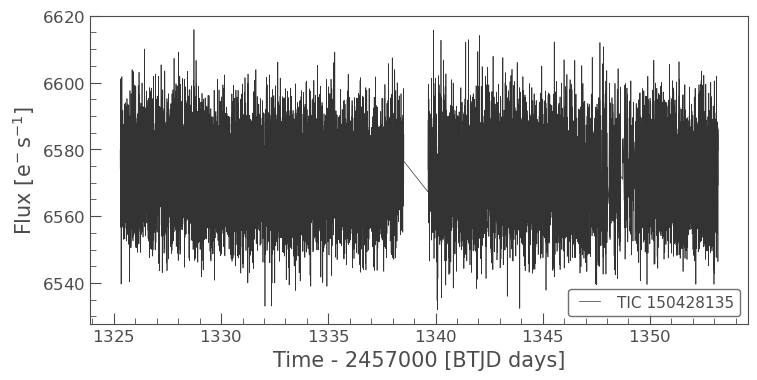

In [4]:
lc = search[0].download()
print(lc.meta["SECTOR"], lc.meta["OBJECT"])
print(lc.columns)
lc.plot();

18279 18279


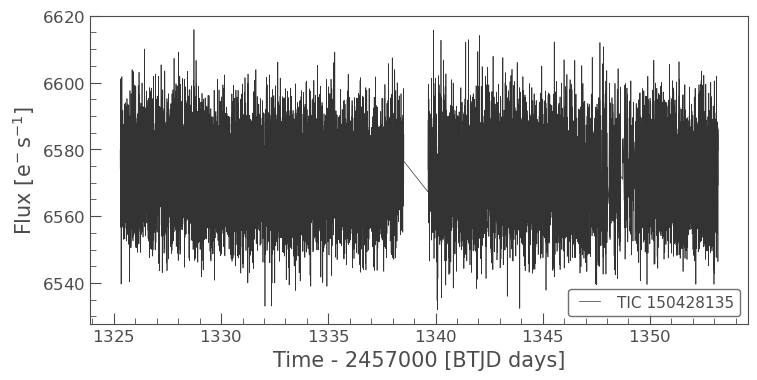

In [5]:
%matplotlib inline
lc_clean = lc.remove_nans()
print(len(lc), len(lc_clean))
lc_clean.plot();